In [4]:
# General imports 
import os 
import re
import numpy as np
import pandas as pd
from pathlib import Path
import scipy.stats as stats 
from skimage import measure
import matplotlib.pyplot as plt
import math

# Pynwb imports
from hdmf_zarr import NWBZarrIO
from nwbwidgets import nwb2widget

import sys
# Add the directory that contains the 'bci' folder
sys.path.insert(0, '/code/src/')  # Note: changed to /code/src/ not /code/src/bci/

# Now these imports should work
from bci.loaders import load
from bci.processing import processing

In [ ]:
def photostim_prepost_frames(epoch_table):
    epoch_table['duration'] = epoch_table.stop_time - epoch_table.start_time
    
    # Define the stimulus names we're looking for
    photo_stimuli = ['photostim', 'photostim_post']
    relevant_epochs = epoch_table[epoch_table['stimulus_name'].isin(photo_stimuli)].copy()
    relevant_epochs['duration'] = relevant_epochs.stop_time - relevant_epochs.start_time
    
    # Set stimulus_name as index for direct access
    indexed_epochs = relevant_epochs.set_index('stimulus_name')
    
    # Now you can directly access by stimulus name and convert to integers
    photostim_pre_start = int(indexed_epochs.loc['photostim'].start_frame)
    photostim_pre_stop = int(indexed_epochs.loc['photostim'].stop_frame)
    photostim_post_start = int(indexed_epochs.loc['photostim_post'].start_frame)
    photostim_post_stop = int(indexed_epochs.loc['photostim_post'].stop_frame)
    
    return photostim_pre_start, photostim_pre_stop, photostim_post_start, photostim_post_stop

def get_roi_centroids(valid_roi_table):
    '''
    Iterate through the image masks in the ROI table, 
    get the indices corresponding to each ROI, 
    then take the average to get the x and y locations of the cell centroid. 
    
    Returns an array with dimensions (n_cells, xy_position)
    '''
    centroids = []
    for mask in valid_roi_table['image_mask']:
        ys, xs = np.where(mask)
        x = np.mean(xs)
        y = np.mean(ys)
        centroids.append((x, y))
    return np.array(centroids)


def correlation_prepost_bci(dff_traces, photostim_pre_start, photostim_pre_stop, 
                           photostim_post_start, photostim_post_stop, valid_roi_table, name_of_file, photostim_neuron=None):
    import numpy as np
    import matplotlib.pyplot as plt
    from scipy import stats
    
    # Index into the dff traces array to limit to the relevant time points
    dff_pre = dff_traces[photostim_pre_start:photostim_pre_stop, :]
    dff_pre = dff_pre.T
    dff_post = dff_traces[photostim_post_start:photostim_post_stop, :]
    dff_post = dff_post.T
                            
    # Limit dff traces for photostimulation activity period before the task to valid ROIs
    dff_pre = dff_pre[valid_roi_table.index.values, :]
    print(f"dff_pre shape: {dff_pre.shape}")
    
    # Limit dff traces for photostimulation activity period after the task to valid ROIs
    dff_post = dff_post[valid_roi_table.index.values, :]
    print(f"dff_post shape: {dff_post.shape}")
    
    # Calculate correlation matrices
    correlations_pre = np.corrcoef(dff_pre)
    correlations_post = np.corrcoef(dff_post)
    
    # Keep only upper triangular part (avoid duplicate pairs and diagonal)
    correlations_pre = np.triu(correlations_pre, k=1)
    correlations_post = np.triu(correlations_post, k=1)
    
    # Statistical comparison
    t, p_val = stats.ttest_ind(correlations_pre.flatten(), correlations_post.flatten())
    print(f"T-test p-value: {p_val}")
    
    # Plot both distributions
    plt.figure(figsize=(10, 6))
    plt.hist(correlations_pre.flatten(), bins=100, color='green', label='pre', histtype='step')
    plt.hist(correlations_post.flatten(), bins=100, color='purple', label='post', histtype='step')
    plt.title('Correlations before and after BCI learning, p=' + str(np.round(p_val, 5)))
    plt.xlabel('Correlation')
    plt.ylabel('# cell pairs')
    plt.xlim(-0.1, 0.1)
    plt.legend()
    #plt.show()
 # Create filename for saving
    
    if photostim_neuron is not None:
        save_name = f"{name_of_file}neuron{photostim_neuron}"
    else:
        save_name = f"{name_of_file}"

    # Save to /scratch folder
    plt.savefig(f"/code/scripts/miguel/Graphs/{save_name}_correlation_plot.png", dpi=300, bbox_inches='tight')
    #plt.close()  # Close the figure to save memory

    return correlations_pre, correlations_post, p_val

In [ ]:
def corr_pval_photostim(name_of_file):
    # This section is pulling in relevant data pieces from nwb files
    data = load.load_session_data(name_of_file)
    dff_traces = data['dff_traces'] 
    
    photostim = data['nwb_file'].stimulus["PhotostimTrials"].to_dataframe()
    photostim_neurons = photostim.closest_roi.unique()
    
    epoch_table = data['epoch_table']
    relevant_epochs = epoch_table[epoch_table['stimulus_name'].isin(photostim['stimulus_name'])].copy()

    # Check that both photostim and photostim_post exist. If not, skip this file
    required_stimuli = ['photostim', 'photostim_post']
    available_stimuli = relevant_epochs.stimulus_name.unique()
    missing_stimuli = [stim for stim in required_stimuli if stim not in available_stimuli]
    
    if missing_stimuli:
        print(f"Skipping {name_of_file}: Missing stimulus types: {missing_stimuli}")
        return None  # Return None to indicate this file was skipped
    
    relevant_epochs['duration'] = relevant_epochs.stop_time-relevant_epochs.start_time
    
    valid_roi_table, cn_index = processing.filter_somas(data=data)
    # You have to unpack the variables in order to be able to use them
    
    photostim_pre_start, photostim_pre_stop, photostim_post_start, photostim_post_stop = photostim_prepost_frames(epoch_table)
    # Data extraction is complete. Data processing continues past this point
    
    # Pre and post activity correlations before and after bci task
    correlations_pre, correlations_post, p_val = correlation_prepost_bci(
    dff_traces, 
    photostim_pre_start, 
    photostim_pre_stop, 
    photostim_post_start, 
    photostim_post_stop, 
    valid_roi_table,
    name_of_file
    )
    
    # Centroids
    # Calculate centroids for each ROI 
    centroids = get_roi_centroids(valid_roi_table)
    centroidX = centroids[:, 0]
    centroidY = centroids[:, 1]
    centroid_cell_1 = centroids[0, :]
    centroid_cell_2 = centroids[1, :]

    math.dist(centroid_cell_1, centroid_cell_2)
    
    pairs_data = []
    for roi_id_1 in range(len(valid_roi_table.index.values)): 
        for roi_id_2 in range(len(valid_roi_table.index.values)): 
            centroid_cell_1 = centroids[roi_id_1, :]
            centroid_cell_2 = centroids[roi_id_2, :]
            distance = math.dist(centroid_cell_1, centroid_cell_2)
            r_value_pre = correlations_pre[roi_id_1, roi_id_2]
            r_value_post = correlations_post[roi_id_1, roi_id_2]
            r_value_diff = r_value_post-r_value_pre
            pairs_data.append([roi_id_1, roi_id_2, r_value_pre, r_value_post, r_value_diff, distance])
            
            
    pairs = pd.DataFrame(pairs_data, columns=['roi_id_1', 'roi_id_2', 'r_value_pre', 'r_value_post', 'r_value_diff', 'distance'])
            
    # Select the top 2000 gene pairs with the largest absolute differences in correlation
    # between conditions, while preserving the original signed values in r_value_diff.
    # This sorts by absolute magnitude but keeps both positive and negative differences.
    top_n = 2000
    top_pairs = pairs.reindex(pairs['r_value_diff'].abs().sort_values(ascending=False).index).head(top_n)       
            
    return data, correlations_pre, correlations_post, p_val, pairs
            
            

BCI data directory: /data/brain-computer-interface

Session directory: /data/brain-computer-interface/single-plane-ophys_767715_2025-02-17_17-41-50_processed_2025-08-05_01-05-20

NWB file: single-plane-ophys_767715_2025-02-17_17-41-50_behavior_nwb
NWB path: /data/brain-computer-interface/single-plane-ophys_767715_2025-02-17_17-41-50_processed_2025-08-05_01-05-20/single-plane-ophys_767715_2025-02-17_17-41-50_behavior_nwb


/opt/conda/lib/python3.10/site-packages/hdmf/spec/namespace.py:535: UserWarning: Ignoring cached namespace 'core' version 2.7.0 because version 2.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."


All threshold files for mouse 767715: ['single-plane-ophys_767715_2025-02-10', 'single-plane-ophys_767715_2025-02-03', 'single-plane-ophys_767715_2025-01-31', 'single-plane-ophys_767715_2025-02-06', 'single-plane-ophys_767715_2025-02-17', 'single-plane-ophys_767715_2025-02-13']

Found threshold file at: /data/bci-thresholds/single-plane-ophys_767715_2025-02-17
total difference in dataframes: 4
CN: [48]
dff_pre shape: (472, 76291)
dff_post shape: (472, 78621)
T-test p-value: 5.051382643848072e-138


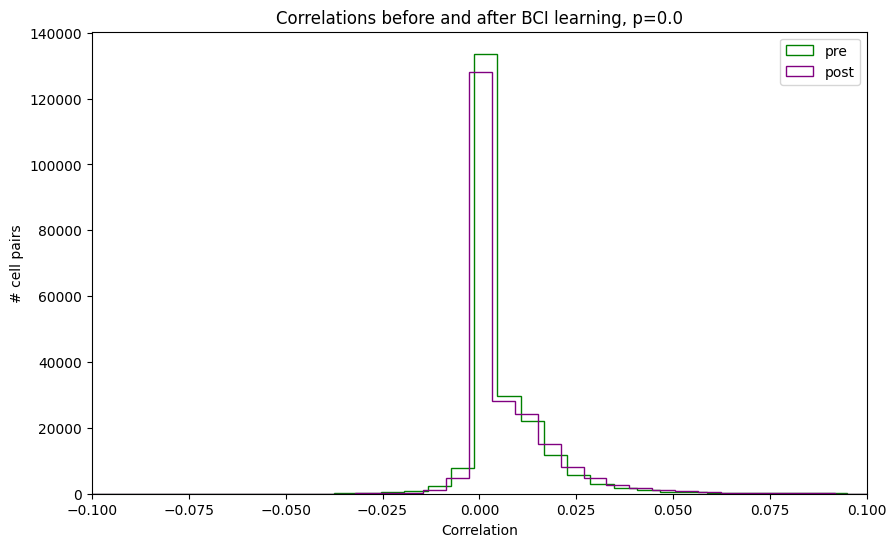

BCI data directory: /data/brain-computer-interface

Session directory: /data/brain-computer-interface/single-plane-ophys_772414_2025-01-27_15-57-05_processed_2025-08-12_02-31-55

NWB file: single-plane-ophys_772414_2025-01-27_15-57-05_behavior_nwb
NWB path: /data/brain-computer-interface/single-plane-ophys_772414_2025-01-27_15-57-05_processed_2025-08-12_02-31-55/single-plane-ophys_772414_2025-01-27_15-57-05_behavior_nwb


/opt/conda/lib/python3.10/site-packages/hdmf/spec/namespace.py:535: UserWarning: Ignoring cached namespace 'core' version 2.7.0 because version 2.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."


All threshold files for mouse 772414: ['single-plane-ophys_772414_2025-02-10', 'single-plane-ophys_772414_2025-02-06', 'single-plane-ophys_772414_2025-01-27']

Found threshold file at: /data/bci-thresholds/single-plane-ophys_772414_2025-01-27
total difference in dataframes: 5
CN: [41]
dff_pre shape: (81, 34651)
dff_post shape: (81, 35576)
T-test p-value: 0.05160353507786085


<Figure size 640x480 with 0 Axes>

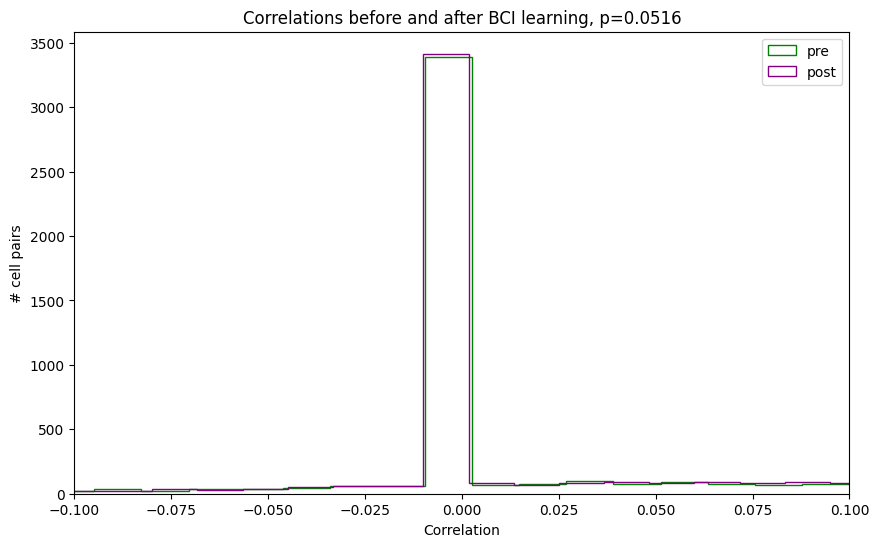

BCI data directory: /data/brain-computer-interface

Session directory: /data/brain-computer-interface/single-plane-ophys_772414_2025-02-06_16-47-44_processed_2025-08-06_18-52-14

NWB file: single-plane-ophys_772414_2025-02-06_16-47-44_behavior_nwb
NWB path: /data/brain-computer-interface/single-plane-ophys_772414_2025-02-06_16-47-44_processed_2025-08-06_18-52-14/single-plane-ophys_772414_2025-02-06_16-47-44_behavior_nwb


/opt/conda/lib/python3.10/site-packages/hdmf/spec/namespace.py:535: UserWarning: Ignoring cached namespace 'core' version 2.7.0 because version 2.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."


All threshold files for mouse 772414: ['single-plane-ophys_772414_2025-02-10', 'single-plane-ophys_772414_2025-02-06', 'single-plane-ophys_772414_2025-01-27']

Found threshold file at: /data/bci-thresholds/single-plane-ophys_772414_2025-02-06
total difference in dataframes: 10
CN: [13]
dff_pre shape: (10, 34027)
dff_post shape: (10, 36472)
T-test p-value: 0.028568285779283262


<Figure size 640x480 with 0 Axes>

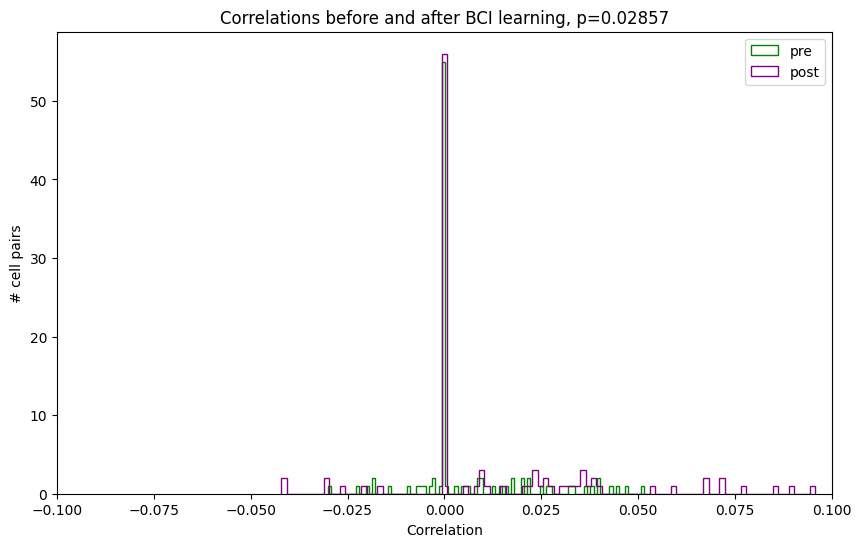

BCI data directory: /data/brain-computer-interface

Session directory: /data/brain-computer-interface/single-plane-ophys_772414_2025-02-10_11-15-26_processed_2025-08-04_23-06-21

NWB file: single-plane-ophys_772414_2025-02-10_11-15-26_behavior_nwb
NWB path: /data/brain-computer-interface/single-plane-ophys_772414_2025-02-10_11-15-26_processed_2025-08-04_23-06-21/single-plane-ophys_772414_2025-02-10_11-15-26_behavior_nwb


/opt/conda/lib/python3.10/site-packages/hdmf/spec/namespace.py:535: UserWarning: Ignoring cached namespace 'core' version 2.7.0 because version 2.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."


All threshold files for mouse 772414: ['single-plane-ophys_772414_2025-02-10', 'single-plane-ophys_772414_2025-02-06', 'single-plane-ophys_772414_2025-01-27']

Found threshold file at: /data/bci-thresholds/single-plane-ophys_772414_2025-02-10
total difference in dataframes: 3
CN: [1075]
dff_pre shape: (16, 70451)
dff_post shape: (16, 33520)
T-test p-value: 0.11860771785808835


<Figure size 640x480 with 0 Axes>

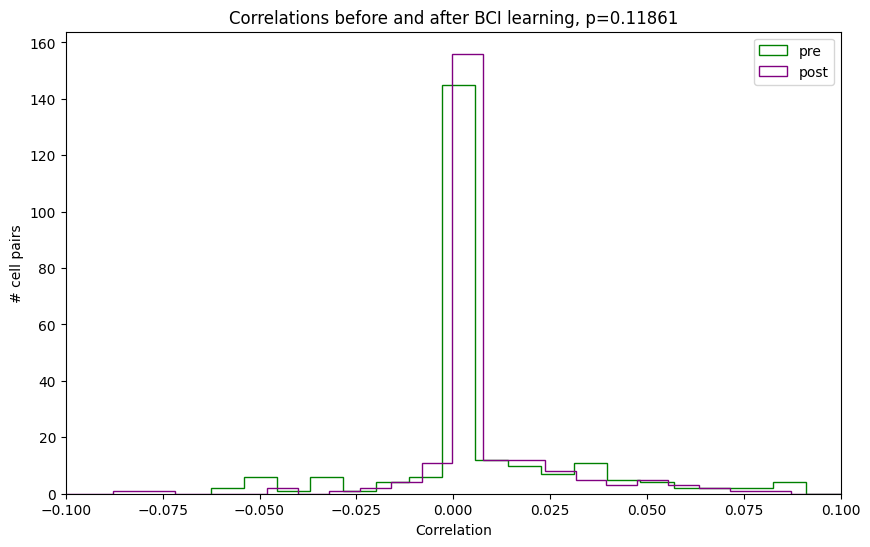

BCI data directory: /data/brain-computer-interface

Session directory: /data/brain-computer-interface/single-plane-ophys_731015_2025-01-31_20-37-19_processed_2025-08-06_05-37-58

NWB file: single-plane-ophys_731015_2025-01-31_20-37-19_behavior_nwb
NWB path: /data/brain-computer-interface/single-plane-ophys_731015_2025-01-31_20-37-19_processed_2025-08-06_05-37-58/single-plane-ophys_731015_2025-01-31_20-37-19_behavior_nwb


/opt/conda/lib/python3.10/site-packages/hdmf/spec/namespace.py:535: UserWarning: Ignoring cached namespace 'core' version 2.7.0 because version 2.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."


All threshold files for mouse 731015: ['single-plane-ophys_731015_2025-01-24', 'single-plane-ophys_731015_2025-01-28', 'single-plane-ophys_731015_2025-01-13', 'single-plane-ophys_731015_2025-01-31', 'single-plane-ophys_731015_2025-01-10']

Found threshold file at: /data/bci-thresholds/single-plane-ophys_731015_2025-01-31
total difference in dataframes: 30
CN: [124]
dff_pre shape: (227, 84794)
dff_post shape: (227, 73830)
T-test p-value: 2.6454616053256688e-139


<Figure size 640x480 with 0 Axes>

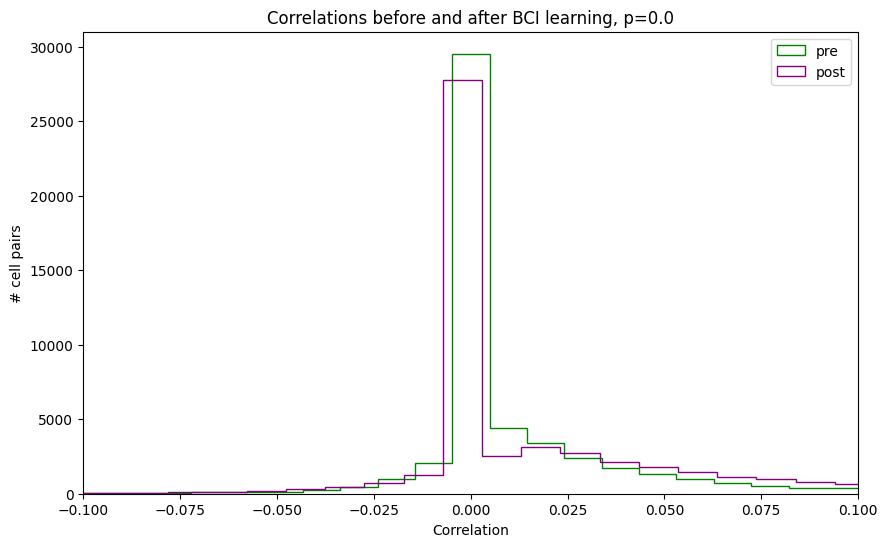

BCI data directory: /data/brain-computer-interface

Session directory: /data/brain-computer-interface/single-plane-ophys_740369_2025-01-09_17-18-37_processed_2025-08-06_03-49-53

NWB file: single-plane-ophys_740369_2025-01-09_17-18-37_behavior_nwb
NWB path: /data/brain-computer-interface/single-plane-ophys_740369_2025-01-09_17-18-37_processed_2025-08-06_03-49-53/single-plane-ophys_740369_2025-01-09_17-18-37_behavior_nwb


/opt/conda/lib/python3.10/site-packages/hdmf/spec/namespace.py:535: UserWarning: Ignoring cached namespace 'core' version 2.7.0 because version 2.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."


All threshold files for mouse 740369: ['single-plane-ophys_740369_2025-01-24', 'single-plane-ophys_740369_2025-02-03', 'single-plane-ophys_740369_2025-01-13', 'single-plane-ophys_740369_2025-01-30', 'single-plane-ophys_740369_2025-02-04', 'single-plane-ophys_740369_2025-02-17', 'single-plane-ophys_740369_2025-01-09']

Found threshold file at: /data/bci-thresholds/single-plane-ophys_740369_2025-01-09
total difference in dataframes: 3
CN: [20]
dff_pre shape: (310, 70955)
dff_post shape: (310, 57307)
T-test p-value: 8.697132338127944e-55


<Figure size 640x480 with 0 Axes>

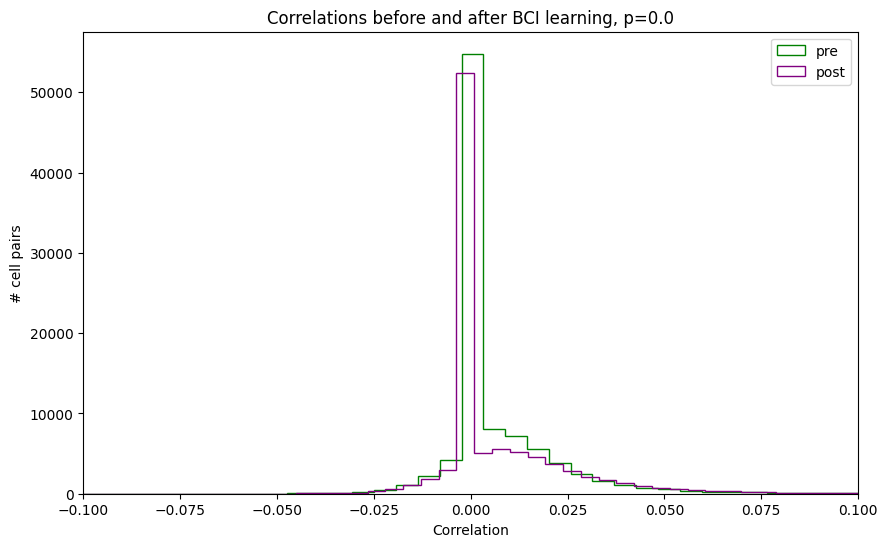

BCI data directory: /data/brain-computer-interface

Session directory: /data/brain-computer-interface/single-plane-ophys_740369_2025-01-13_17-31-04_processed_2025-08-04_17-59-13

NWB file: single-plane-ophys_740369_2025-01-13_17-31-04_behavior_nwb
NWB path: /data/brain-computer-interface/single-plane-ophys_740369_2025-01-13_17-31-04_processed_2025-08-04_17-59-13/single-plane-ophys_740369_2025-01-13_17-31-04_behavior_nwb


/opt/conda/lib/python3.10/site-packages/hdmf/spec/namespace.py:535: UserWarning: Ignoring cached namespace 'core' version 2.7.0 because version 2.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."


All threshold files for mouse 740369: ['single-plane-ophys_740369_2025-01-24', 'single-plane-ophys_740369_2025-02-03', 'single-plane-ophys_740369_2025-01-13', 'single-plane-ophys_740369_2025-01-30', 'single-plane-ophys_740369_2025-02-04', 'single-plane-ophys_740369_2025-02-17', 'single-plane-ophys_740369_2025-01-09']

Found threshold file at: /data/bci-thresholds/single-plane-ophys_740369_2025-01-13
total difference in dataframes: 56
CN: [135]


In [ ]:
metadata = load.load_filtered_metadata()
for name_of_file in metadata.name.values:
    # Make sure to check data type for proper storing
    result = corr_pval_photostim(name_of_file)
    if result is not None:  # Check if file was processed successfully
        [data, correlations_pre, correlations_post, p_val, pairs] = result